In [ ]:
### 0) Setup and Imports

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
from shapely.geometry import Point
from matplotlib.lines import Line2D
import numpy as np
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel, RationalQuadratic
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold

In [ ]:
### 1) Import CSV Ecohydro Data

FT_TO_M = 0.3048
FT_PER_S_TO_M_PER_S = 0.3048
M_PER_S_TO_FT_PER_S = 3.28084

# Keep ALL spatial data in feet:
# - downstream_dist (feet)
# - distance_to_centerline (feet)  
# - upstream_depth (feet)
# - depth1 (feet)
# - velocity1 (ft/s)
# - Easting/Northing (feet)

complete_data_25 = pd.read_csv("data/25_ecohydro_data.csv")
complete_data_25_crs = "ESRI:102690"
print(complete_data_25.columns)

complete_data_26 = pd.read_csv("data/26_ecohydro_data.csv")
complete_data_26_crs = "ESRI:102690"
print(complete_data_26.columns)

# Combine the 2 years of data into one csv by matching columns and appending the data
complete_data = pd.concat([complete_data_25, complete_data_26], ignore_index=True)
print(complete_data.size)

Index(['Collection Date', 'Collection Time', 'Northing', 'Easting',
       'Elevation', 'Longitude', 'Latitude', 'Global_ID_Eco', 'Type',
       'Transect ID', 'Section', 'Measurement Point ID', 'Reading Number',
       'Total depth', 'Depth', 'Depth 2', 'Actual depth', 'Velocity 1',
       'Velocity 2', 'Point Notes', 'SMB Presence', 'Bank Measurement Began',
       'Investigators', 'Unnamed: 23', 'Unnamed: 24'],
      dtype='object')


In [ ]:
### 2) Import Upstream Depth

# Read in the depth
depth_data_mm_25 = pd.read_csv('data/25_depthSensorData', skiprows=3)
depth_data_mm_26 = pd.read_csv('data/26_depthSensorData', skiprows=3)

# Combine the 2 years of data into one csv by appending the csvs
depth_data_mm = pd.concat([depth_data_mm_25, depth_data_mm_26], ignore_index=True)

# Convert datetime columns to pandas datetime and set as index for resampling
depth_data_mm['_time'] = pd.to_datetime(depth_data_mm['_time'])
depth_data_mm = depth_data_mm.set_index('_time')

# Aggregate depth data
depth_interval_minutes = 300
depth_agg = depth_data_mm['_value'].resample(f'{depth_interval_minutes}min').median()
print('Depth resampling successful')

# Remove NaN values from aggregation
depth_agg = depth_agg.dropna()
print(f'Size of depth_agg: {depth_agg.shape}')

# Depth outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
depth_mean = depth_agg.mean()
depth_std = depth_agg.std()
depth_mask = np.abs(depth_agg - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg[depth_mask]

# Convert depth data from mm to feet and create DataFrame
depth_agg_final = (7313.2 - depth_agg_trimmed) * 0.00328084  ### FINAL

# Outlier trimming (same threshold)
depth_mean = depth_agg_final.mean()
depth_std = depth_agg_final.std()
depth_mask = np.abs(depth_agg_final - depth_mean) <= outlier_std_threshold * depth_std
depth_agg_trimmed = depth_agg_final[depth_mask]

# Convert from mm to feet and append to the 2025 depth series
depth_agg_final = (7313.2 - depth_agg_trimmed) * 0.00328084
depth_agg_final = pd.concat([depth_agg_final, depth_agg_final_26]).sort_index()
print(f'Combined depth series: {len(depth_agg_final)} points '
      f'({depth_agg_final.index.min().date()} to {depth_agg_final.index.max().date()})')

# Convert Collection Date to pandas datetime
# format='mixed' parses each value individually, handling native Excel datetimes,
# M/D/YYYY text dates (e.g. "6/6/2026"), and dates with times (e.g. "6/6/2025 16:00")
# dayfirst=False ensures M/D/YYYY (month-first) interpretation
complete_data['Collection Date'] = pd.to_datetime(
    complete_data['Collection Date'], format='mixed', dayfirst=False
)

# Extract date only (without time) for matching
# Note: depth_agg_final already have DatetimeIndex
complete_data['Date'] = complete_data['Collection Date'].dt.date

# Create aggregated daily averages for depth data
# The index is already datetime, so we can convert to date and group
depth_daily = depth_agg_final.groupby(depth_agg_final.index.date).mean().to_dict()

# Create new columns initialized with NaN
complete_data['upstream_depth'] = np.nan

# Match and fill data based on date only
for idx, row in complete_data.iterrows():
    obs_date = row['Date']
    
    # Find matching depth measurement for this date
    if obs_date in depth_daily:
        complete_data.at[idx, 'upstream_depth'] = depth_daily[obs_date]

# Clean up temporary Date column
complete_data = complete_data.drop(columns=['Date'])

# Print summary of matched data points
print("\nData matching summary:")   
print(f"Total points in complete_data: {len(complete_data)}")
print(f"Points with upstream depth data: {complete_data['upstream_depth'].notna().sum()}")

Depth resampling successful
Size of depth_agg: (605,)
2026 depth resampling successful, size: (188,)
Combined depth series: 781 points (2025-05-30 to 2026-06-11)

Data matching summary:
Total points in complete_data: 2093
Points with upstream depth data: 2081


In [ ]:
### 3) Sontek Velocity upload and merge

# Read in the velocity
sontek_data = pd.read_csv('data/25_ADCPData.csv', skiprows=3)

# Convert datetime columns to pandas datetime and set as index for resampling
sontek_data['_time'] = pd.to_datetime(sontek_data['_time'])
sontek_data = sontek_data.set_index('_time')

# Aggregate sontek velocity data
sontek_interval_minutes = 300
sontek_agg = sontek_data['_value'].resample(f'{sontek_interval_minutes}min').median()
print('Sontek resampling successful')

# Remove NaN values from aggregation
sontek_agg = sontek_agg.dropna()
print(f'Aggregated data shape: {sontek_agg.shape}')

# Sontek outlier trimming
outlier_std_threshold = 2.0  # Define the threshold for outlier detection (2 standard deviations)
sontek_mean = sontek_agg.mean()
sontek_std = sontek_agg.std()
sontek_mask = np.abs(sontek_agg - sontek_mean) <= outlier_std_threshold * sontek_std
sontek_agg_final = sontek_agg[sontek_mask]

# Create a DataFrame from the aggregated sontek velocity data
sontek_df = pd.DataFrame({
    'Collection Date': sontek_agg_final.index,   # _time from velocity data
    'Velocity': sontek_agg_final.values,         # aggregated velocity values
    'Depth': 1,                                  # set Depth to 1 for all velocity points
    'Northing': 319995.5,                        # constant Northing for sontek location
    'Easting': 13244857,                         # constant Easting for sontek location
    'Type': 'Sontek'                             # add Type column for plotting model dependencies
})

# Match upstream_depth for sontek data based on date (using depth_daily from cell 2)
sontek_df['upstream_depth'] = sontek_df['Collection Date'].apply(
    lambda dt: depth_daily.get(dt.date(), np.nan)
)
print(f"Sontek points with upstream_depth matched: {sontek_df['upstream_depth'].notna().sum()} / {len(sontek_df)}")

# Append the sontek velocity data to complete_data
complete_data = pd.concat([complete_data, sontek_df], ignore_index=True)

# Print summary of added data points
print(f"\nSontek velocity data appended to complete_data")
print(f"  Points added: {len(sontek_df)}")
print(f"  New total rows in complete_data: {len(complete_data)}")

Sontek resampling successful
Aggregated data shape: (508,)
Sontek points with upstream_depth matched: 475 / 475

Sontek velocity data appended to complete_data
  Points added: 475
  New total rows in complete_data: 3043


In [40]:
# Stats on number of points by velocity band, correlated to upstream depth bands (low <2.6 ft, high >3.1 ft)

# Define velocity bands (edit as needed based on domain):
# Low velocity: < 0.25 ft/s
# Middle velocity: 0.25 - 1.0 ft/s
# High velocity: > 1.0 ft/s
def velocity_band(v):
    if v < 0.25:
        return "Low"
    elif v <= 1.0:
        return "Middle"
    else:
        return "High"

# Define upstream depth band function
def upstream_depth_band(depth):
    if depth < 2.6:
        return "Low upstream depth (<2.6 ft)"
    elif depth > 3.1:
        return "High upstream depth (>3.1 ft)"
    else:
        return "Mid upstream depth (2.6-3.1 ft)"

# Apply bands to data (skip NA velocities!):
complete_data['velocity_band'] = complete_data['Velocity'].apply(velocity_band)
complete_data['upstream_depth_band'] = complete_data['upstream_depth'].apply(upstream_depth_band)

# Crosstab count of velocity band by upstream depth band
velocity_depth_counts = pd.crosstab(complete_data['velocity_band'], complete_data['upstream_depth_band'])

print("\nNumber of points by velocity band and upstream depth band:")
print(velocity_depth_counts)

# Also, just numbers for each combination
for depth_band in ['Low upstream depth (<2.6 ft)', 'Mid upstream depth (2.6-3.1 ft)', 'High upstream depth (>3.1 ft)']:
    print(f"\nStats for {depth_band}:")
    subset = complete_data[complete_data['upstream_depth_band'] == depth_band]
    low = (subset['velocity_band'] == 'Low').sum()
    mid = (subset['velocity_band'] == 'Middle').sum()
    high = (subset['velocity_band'] == 'High').sum()
    total = len(subset)
    print(f"  Low velocity (<0.25): {low}")
    print(f"  Middle velocity (0.25-1.0): {mid}")
    print(f"  High velocity (>1.0): {high}")
    print(f"  Total: {total}")


Number of points by velocity band and upstream depth band:
upstream_depth_band  High upstream depth (>3.1 ft)  \
velocity_band                                        
Low                                            118   

upstream_depth_band  Low upstream depth (<2.6 ft)  \
velocity_band                                       
Low                                           336   

upstream_depth_band  Mid upstream depth (2.6-3.1 ft)  
velocity_band                                         
Low                                              496  

Stats for Low upstream depth (<2.6 ft):
  Low velocity (<0.25): 336
  Middle velocity (0.25-1.0): 0
  High velocity (>1.0): 0
  Total: 336

Stats for Mid upstream depth (2.6-3.1 ft):
  Low velocity (<0.25): 496
  Middle velocity (0.25-1.0): 0
  High velocity (>1.0): 0
  Total: 496

Stats for High upstream depth (>3.1 ft):
  Low velocity (<0.25): 118
  Middle velocity (0.25-1.0): 0
  High velocity (>1.0): 0
  Total: 118


In [37]:
### 4) Data Trimming Based on Depth of Measurement and Velocity Magnitude
# only measurement depths below 1 foot will be considered
# measurement depth is varaible "Depth"
# "Actual depth" seems like some sort of systematic thing

# Print initial size
initial_count = len(complete_data)

# Keep only "Middle" section data for this iteration (case-insensitive: data contains
# both "Middle" and "middle"). Sontek rows have no Section value, so keep them too.
section_mask = (
    complete_data['Section'].str.strip().str.lower().eq('middle')
    | complete_data['Type'].eq('Sontek')
)
section_trimmed = complete_data[section_mask]
section_trimmed_count = len(section_trimmed)
print(f"Rows after Section == 'Middle' filter (Sontek kept): {section_trimmed_count} (removed {initial_count - section_trimmed_count})")

# Trim based on depth >= 1
depth_trimmed = section_trimmed[section_trimmed['Depth'] <= 1]
depth_trimmed_count = len(depth_trimmed)
print(f"Rows after depth <= 1 filter: {depth_trimmed_count} (removed {initial_count - depth_trimmed_count})")

# Trim based on velocity >= 0
vel1_trimmed = depth_trimmed[depth_trimmed['Velocity'] >= 0]
vel1_trimmed_count = len(vel1_trimmed)
print(f"Rows after velocity >= 0 filter: {vel1_trimmed_count} (removed {depth_trimmed_count - vel1_trimmed_count}, total removed: {initial_count - vel1_trimmed_count})")

final_trimmed = vel1_trimmed[vel1_trimmed['Velocity'] <= 3.2]
final_trimmed_count = len(final_trimmed)
print(f"Rows after velocity <= 3.2 filter: {final_trimmed_count} (removed {vel1_trimmed_count - final_trimmed_count}, total removed: {initial_count - final_trimmed_count})")

print(f"Total Data Rows for GP Model: {final_trimmed_count}")


# Assign the trimmed dataframe back to complete_data (use .copy() to avoid SettingWithCopyWarning)
complete_data = final_trimmed.copy()

Rows after Section == 'Middle' filter (Sontek kept): 2382 (removed 661)
Rows after depth <= 1 filter: 1747 (removed 1296)
Rows after velocity >= 0 filter: 950 (removed 797, total removed: 2093)
Rows after velocity <= 3.2 filter: 950 (removed 0, total removed: 2093)
Total Data Rows for GP Model: 950


Skipping field time1: unsupported OGR type: 10
Skipping field time2: unsupported OGR type: 10


Original centerline CRS: EPSG:4269
Original complete_data_25FINAL CRS: PROJCS["NAD_1983_StatePlane_Michigan_South_FIPS_2113_Feet",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",41.5],PARAMETER["central_meridian",-84.3666666666667],PARAMETER["standard_parallel_1",42.1],PARAMETER["standard_parallel_2",43.6666666666667],PARAMETER["false_easting",13123333.3333333],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102690"]]
Converted centerline CRS: PROJCS["NAD_1983_StatePlane_Michigan_South_FIPS_2113_Feet",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.25

C:\Users\kland\AppData\Local\Temp\ipykernel_39272\3947846240.py:49: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  centerline.plot(ax=ax, color='red', linewidth=2, label='River Centerline')
C:\Users\kland\AppData\Local\Temp\ipykernel_39272\3947846240.py:55: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(bbox_minx - x_buffer, bbox_maxx + x_buffer)
C:\Users\kland\AppData\Local\Temp\ipykernel_39272\3947846240.py:56: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  ax.set_ylim(bbox_miny - y_buffer, bbox_maxy + y_buffer)


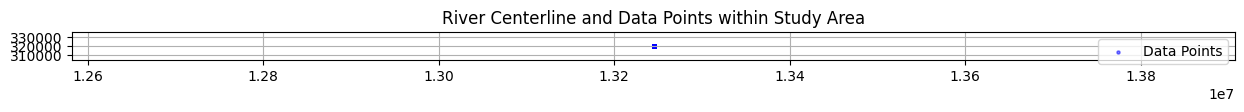

In [38]:
### 5) Centerline Import and Trimming

# Import centerline GeoJSON
centerline = gpd.read_file("Huron_RiverSystem.geojson")
print(f"Original centerline CRS: {centerline.crs}")

# Import complete_data_25FINAL GeoJSON
complete_data_25FINAL = gpd.read_file("complete_data_25FINAL.geojson")
print(f"Original complete_data_25FINAL CRS: {complete_data_25FINAL.crs}")

# Convert centerline CRS to match complete_data CRS
centerline = centerline.to_crs(complete_data_25FINAL.crs)
print(f"Converted centerline CRS: {centerline.crs}")

### Trim the Massive Centerline File to Match Data Size
# Get the min/max bounds of Easting (X) and Northing (Y) columns
x_min = complete_data["Easting"].min()
x_max = complete_data["Easting"].max()
y_min = complete_data["Northing"].min()
y_max = complete_data["Northing"].max()

print("\nData bounds:")
print(f"X: {x_min:.1f} to {x_max:.1f}")
print(f"Y: {y_min:.1f} to {y_max:.1f}")

# Create a bounding box polygon using (minx, miny, maxx, maxy)
from shapely.geometry import box
bbox = box(x_min, y_min, x_max, y_max)

# Clip centerline to data bounds
centerline_clipped = centerline[centerline.geometry.intersects(bbox)]

print(f"\nCenterline features reduced from {len(centerline)} to {len(centerline_clipped)}")

# Update centerline variable to use clipped version
centerline = centerline_clipped

### Visualize the Centerline and Data Overlapped
# Create a bounding box for visualization
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox], crs=complete_data_crs)

# Create figure and axis
fig, ax = plt.subplots(figsize=(15, 10))

# Plot the complete data points
scatter = ax.scatter(complete_data["Easting"], complete_data["Northing"], color='blue', alpha=0.5, s=5, label='Data Points')

# Plot the centerline
centerline.plot(ax=ax, color='red', linewidth=2, label='River Centerline')

# Set the plot bounds to match the bbox bounds with small buffer
bbox_minx, bbox_miny, bbox_maxx, bbox_maxy = bbox.bounds
x_buffer = (bbox_maxx - bbox_minx) * 0.05  # 5% buffer
y_buffer = (bbox_maxy - bbox_miny) * 0.05  # 5% buffer
ax.set_xlim(bbox_minx - x_buffer, bbox_maxx + x_buffer)
ax.set_ylim(bbox_miny - y_buffer, bbox_maxy + y_buffer)

# Add title and legend
plt.title('River Centerline and Data Points within Study Area')
plt.legend()

# Add gridlines
ax.grid(True)

# Show the plot
plt.show()


In [39]:
### 6) Distance to Centerline Calc
# Calculate distance from each point in complete_data (CSV) to the centerline
# Takes about 8 minutes to complete first pass; 3 mins otherwise

from shapely.geometry import LineString, MultiLineString

# Combine all centerline geometries into a single geometry
centerline_union = centerline.geometry.union_all()

# Save the variable for consistency in inverting back to lat long for visualization
centerline_union_for_inversion = centerline_union

def signed_distance(point, line):
    """
    Calculate signed distance from a point to a line.
    Negative = left side of line, Positive = right side of line.
    """
    if point is None:
        return None
    
    # Calculate the distance
    distance = point.distance(line)
    
    # Find the nearest point on the line
    nearest_point = line.interpolate(line.project(point))
    
    # Handle both LineString and MultiLineString
    all_coords = []
    if isinstance(line, MultiLineString):
        # Extract coordinates from all component LineStrings
        for linestring in line.geoms:
            all_coords.extend(list(linestring.coords))
    else:
        # Single LineString
        all_coords = list(line.coords)
    
    # Find which segment the nearest point is on
    min_dist = float('inf')
    segment_start = None
    segment_end = None
    
    for i in range(len(all_coords) - 1):
        seg_line = LineString([all_coords[i], all_coords[i + 1]])
        dist_to_seg = nearest_point.distance(seg_line)
        if dist_to_seg < min_dist:
            min_dist = dist_to_seg
            segment_start = all_coords[i]
            segment_end = all_coords[i + 1]
    
    # Calculate cross product to determine side
    # Vector from segment start to end
    dx = segment_end[0] - segment_start[0]
    dy = segment_end[1] - segment_start[1]
    
    # Vector from segment start to point
    px = point.x - segment_start[0]
    py = point.y - segment_start[1]
    
    # Cross product: positive means point is to the left, negative means right
    cross_product = dx * py - dy * px
    
    # Return negative distance for left side, positive for right side
    return -distance if cross_product > 0 else distance

# Create Point geometries from Easting/Northing columns in complete_data
print("Creating point geometries from Easting/Northing columns...")
complete_data['geometry'] = complete_data.apply(
    lambda row: Point(row['Easting'], row['Northing']) if pd.notna(row['Easting']) and pd.notna(row['Northing']) else None,
    axis=1
)

# Calculate signed distance to centerline for each point
print("Calculating distances to centerline...")
complete_data['distance_to_centerline'] = complete_data['geometry'].apply(
    lambda point: signed_distance(point, centerline_union)
)

print("\nDistance statistics (in feet):")
print(f"Valid distances: {complete_data['distance_to_centerline'].notna().sum()}")
print(f"Null distances: {complete_data['distance_to_centerline'].isna().sum()}")
print(f"Min distance: {complete_data['distance_to_centerline'].min():.2f}")
print(f"Max distance: {complete_data['distance_to_centerline'].max():.2f}")
print(f"Mean distance: {complete_data['distance_to_centerline'].mean():.2f}")

# Filter out points with distance to centerline > 150 feet (outliers)
DISTANCE_THRESHOLD = 150  # feet
original_count = len(complete_data)
complete_data = complete_data[abs(complete_data['distance_to_centerline']) <= DISTANCE_THRESHOLD].copy()
filtered_count = len(complete_data)

print(f"\nOutlier filtering results (threshold: {DISTANCE_THRESHOLD} ft):")
print(f"Original number of points: {original_count}")
print(f"Points after filtering: {filtered_count}")
print(f"Number of outliers removed: {original_count - filtered_count}")
print(f"Percentage of data retained: {(filtered_count/original_count)*100:.1f}%")

### Plot the results to debug
plt.figure(figsize=(12, 7))
plt.scatter(complete_data['distance_to_centerline'], complete_data['Northing'], s=8, alpha=0.7)
plt.xlabel("Distance to Centerline (ft)")
plt.ylabel("Northing")
plt.title("Distance to Centerline vs Northing")
plt.grid(True)
plt.show()


Creating point geometries from Easting/Northing columns...
Calculating distances to centerline...


NotImplementedError: Sub-geometries may have coordinate sequences, but multi-part geometries do not

Projecting all data points onto centerline...
Reference Distance for Calc = 263767.84 feet
Y-coordinate of this point: 320244.01
Highest Y-coordinate in dataset: 320244.01
Reference distance along centerline: 263767.84 feet

Downstream distances calculated for 1393 points
Distance range: 0.0 to 1826.1 feet
✓ All distances are non-negative (as expected)


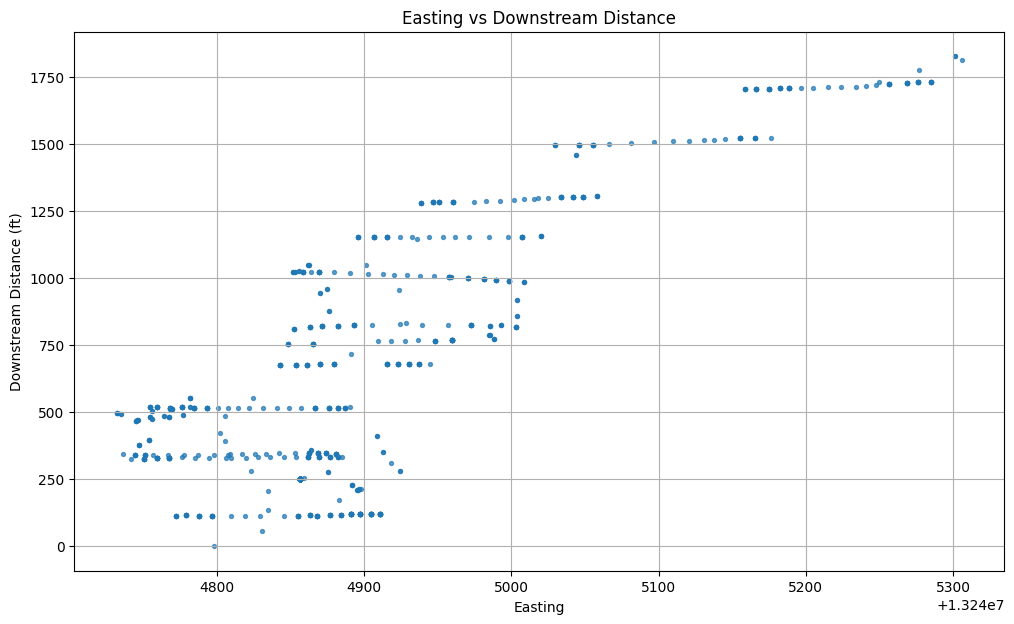

In [9]:
### 7) Downstream Distance Calc
# Calculate downstream distance along the centerline for each point in complete_data
# Uses centerline_union from the distance to centerline calculation (cell 7)

# First pass: project all data points onto centerline and find their distances
print("Projecting all data points onto centerline...")
projected_distances = []

for idx, row in complete_data.iterrows():
    point = row['geometry']
    if point is not None:
        # Project point onto centerline to get distance along the line
        distance_along_centerline = centerline_union.project(point)
    else:
        distance_along_centerline = np.nan
    projected_distances.append(distance_along_centerline)

# Find the minimum distance along centerline (this is the "upstream-most" or "northmost" point)
valid_distances = [d for d in projected_distances if not np.isnan(d)]
min_distance_idx = projected_distances.index(min(valid_distances))
reference_distance = min(valid_distances)
# MAKE SURE THIS IS THE SAME REFERENCE POINT WHICH IS USED LATER FOR TRANSLATION OF MODEL BACK TO LAT LONG!

print(f"Reference Distance for Calc = {reference_distance:.2f} feet")

# Get the actual data point that is northmost along the centerline
northmost_data_point = complete_data.iloc[min_distance_idx]['geometry']

# Get max Y coordinate from geometry column
max_y = max(row['geometry'].y for row in complete_data.to_dict('records') if row['geometry'] is not None)

print(f"Y-coordinate of this point: {northmost_data_point.y:.2f}")
print(f"Highest Y-coordinate in dataset: {max_y:.2f}")
print(f"Reference distance along centerline: {reference_distance:.2f} feet")

# Calculate downstream distances relative to the northmost data point
downstream_distances = []

for distance_along_centerline in projected_distances:
    if np.isnan(distance_along_centerline):
        downstream_distances.append(np.nan)
    else:
        # Calculate relative distance from northmost data point
        downstream_distance = distance_along_centerline - reference_distance
        downstream_distances.append(downstream_distance)

# Add downstream distance to dataframe
complete_data['downstream_dist'] = downstream_distances

print(f"\nDownstream distances calculated for {len(downstream_distances)} points")
print(f"Distance range: {min(valid_distances) - reference_distance:.1f} to {max(valid_distances) - reference_distance:.1f} feet")

# Verify no negative distances
negative_count = sum(1 for d in downstream_distances if not np.isnan(d) and d < -0.01)  # Allow small floating point errors
if negative_count > 0:
    print(f"WARNING: {negative_count} points have negative distances (should be 0)")
else:
    print("✓ All distances are non-negative (as expected)")

### Plot the results to debug
plt.figure(figsize=(12, 7))
plt.scatter(complete_data['Easting'], complete_data['downstream_dist'], s=8, alpha=0.7)
plt.xlabel("Easting")
plt.ylabel("Downstream Distance (ft)")
plt.title("Easting vs Downstream Distance")
plt.grid(True)
plt.show()


In [ ]:
# Save the complete_data DataFrame to a CSV file in the current folder
complete_data.to_csv('complete_data_export.csv', index=False)
print("complete_data DataFrame has been exported to 'complete_data_export.csv'")

Type of complete_data: <class 'pandas.core.frame.DataFrame'>
complete_data DataFrame has been exported to 'complete_data_export.csv'


In [ ]:
### 8) 3 Input GP
# Takes about 30 mins to run
# Details: 
# 3-Variable Gaussian Process Regression Model (SI UNITS)
# Inputs: upstream_depth (m), downstream_dist (m), distance_to_centerline (m)
# Output: Velocity (m/s)
# Kernel: RBF + RationalQuadratic
# *Data converted from Imperial (ft, ft/s) to SI (m, m/s)

print("="*80)
print("3-VARIABLE GAUSSIAN PROCESS REGRESSION MODEL (SI UNITS)")
print("="*80)

# Define input and output columns - CHANGE THESE AS NEEDED
input_columns_3v = ['upstream_depth', 'downstream_dist', 'distance_to_centerline']
output_column_3v = 'Velocity'

print(f"\nModel Configuration:")
print(f"  Input Variables: {', '.join(input_columns_3v)}")
print(f"  Output Variable: {output_column_3v}")
print(f"  Kernel Type: RBF + RationalQuadratic")
print(f"  Units: SI (meters, m/s)")
print(f"  Conversion Factor: 1 ft = {FT_TO_M} m")

# Filter data to only include rows with non-null values for all required columns
gp_data_3v = complete_data[
    complete_data[input_columns_3v[0]].notna() & 
    complete_data[input_columns_3v[1]].notna() & 
    complete_data[input_columns_3v[2]].notna() &
    complete_data[output_column_3v].notna()
].copy()

print(f"\nData Summary:")
print(f"  Total points in streambed dataset: {len(complete_data)}")
print(f"  Points with all required data: {len(gp_data_3v)}")
print(f"  Data coverage: {len(gp_data_3v)/len(complete_data)*100:.1f}%")

# Define units for each column (SI units)
column_units_3v = {
    'Velocity': 'm/s',
    'upstream_depth': 'm',
    'downstream_dist': 'm',
    'distance_to_centerline': 'm',
    'Depth': 'm'
}

# Create readable labels from column names
def format_label_3v(col_name):
    """Convert column name to readable label"""
    return col_name.replace('_', ' ').title()

# Get units for current columns
input_unit_1_3v = column_units_3v.get(input_columns_3v[0], '')
input_unit_2_3v = column_units_3v.get(input_columns_3v[1], '')
input_unit_3_3v = column_units_3v.get(input_columns_3v[2], '')
output_unit_3v = column_units_3v.get(output_column_3v, '')

# Create labels with units
input_label_1_3v = f"{format_label_3v(input_columns_3v[0])} ({input_unit_1_3v})" if input_unit_1_3v else format_label_3v(input_columns_3v[0])
input_label_2_3v = f"{format_label_3v(input_columns_3v[1])} ({input_unit_2_3v})" if input_unit_2_3v else format_label_3v(input_columns_3v[1])
input_label_3_3v = f"{format_label_3v(input_columns_3v[2])} ({input_unit_3_3v})" if input_unit_3_3v else format_label_3v(input_columns_3v[2])
output_label_3v = f"{format_label_3v(output_column_3v)} ({output_unit_3v})" if output_unit_3v else format_label_3v(output_column_3v)

# ===== CONVERT FROM IMPERIAL TO SI UNITS =====
print(f"\nConverting units from Imperial to SI...")
print(f"  Original data in: ft, ft/s")
print(f"  Converted to: m, m/s")

# Convert the DataFrame columns FIRST (so everything downstream uses SI)
for col in input_columns_3v:
    gp_data_3v[col] = gp_data_3v[col] * FT_TO_M
gp_data_3v[output_column_3v] = gp_data_3v[output_column_3v] * FT_TO_M

# Prepare input features (X) and target variable (y) - already in SI now
X_3v = gp_data_3v[input_columns_3v].values        # ← now extracts SI units
y_3v = gp_data_3v[output_column_3v].values        # ← now in m/s
print(f"DataFrame converted to SI units")

print(f"\nFeature shapes:")
print(f"  X (inputs): {X_3v.shape}")
print(f"  y (target): {y_3v.shape}")

print(f"\nFeature statistics:")
print(f"  {input_label_1_3v} range: [{X_3v[:, 0].min():.3f}, {X_3v[:, 0].max():.3f}]")
print(f"  {input_label_2_3v} range: [{X_3v[:, 1].min():.3f}, {X_3v[:, 1].max():.3f}]")
print(f"  {input_label_3_3v} range: [{X_3v[:, 2].min():.3f}, {X_3v[:, 2].max():.3f}]")
print(f"  {output_label_3v} range: [{y_3v.min():.3f}, {y_3v.max():.3f}]")

####### Define the GP kernel - RBF + RationalQuadratic ############# KERNEL ################
kernel_3v = C(1.0, (0.1, 10.0)) * (RBF([5.0, 5.0, 5.0], (0.1, 100.0)) + RationalQuadratic(length_scale=5.0, alpha=1.0, length_scale_bounds=(0.1, 100.0), alpha_bounds=(0.1, 10.0))) + WhiteKernel(0.1, (1e-3, 1.0))

## K-FOLD CROSS-VALIDATION
print("\n" + "-"*80)
print("Performing 5-Fold Cross-Validation...")
print("-"*80)

n_folds = 5
kfold = KFold(n_splits=n_folds, shuffle=True, random_state=42)

cv_r2_scores = []
cv_rmse_scores = []
cv_mae_scores = []

for fold_idx, (train_idx, val_idx) in enumerate(kfold.split(X_3v)):
    # Split data for this fold
    X_train_cv, X_val_cv = X_3v[train_idx], X_3v[val_idx]
    y_train_cv, y_val_cv = y_3v[train_idx], y_3v[val_idx]
    
    # Scale on training fold only (prevents data leakage)
    scaler_X_cv = StandardScaler()
    scaler_y_cv = StandardScaler()
    
    X_train_scaled_cv = scaler_X_cv.fit_transform(X_train_cv)
    y_train_scaled_cv = scaler_y_cv.fit_transform(y_train_cv.reshape(-1, 1)).ravel()
    X_val_scaled_cv = scaler_X_cv.transform(X_val_cv)
    
    # Train GP on this fold
    gp_cv = GaussianProcessRegressor(
        kernel=kernel_3v,
        n_restarts_optimizer=15,
        alpha=1e-6,
        normalize_y=False,
        random_state=42
    )
    gp_cv.fit(X_train_scaled_cv, y_train_scaled_cv)
    
    # Predict on validation fold
    y_val_pred_scaled = gp_cv.predict(X_val_scaled_cv)
    y_val_pred = scaler_y_cv.inverse_transform(y_val_pred_scaled.reshape(-1, 1)).ravel()
    
    # Calculate fold metrics
    fold_r2 = r2_score(y_val_cv, y_val_pred)
    fold_rmse = np.sqrt(mean_squared_error(y_val_cv, y_val_pred))
    fold_mae = mean_absolute_error(y_val_cv, y_val_pred)
    
    cv_r2_scores.append(fold_r2)
    cv_rmse_scores.append(fold_rmse)
    cv_mae_scores.append(fold_mae)
    
    print(f"  Fold {fold_idx + 1}: R2 = {fold_r2:.4f}, RMSE = {fold_rmse:.4f}, MAE = {fold_mae:.4f}")

# Store CV metrics for use in visualizations (these are the TRUE generalization metrics)
cv_r2_mean = np.mean(cv_r2_scores)
cv_r2_std = np.std(cv_r2_scores)
cv_rmse_mean = np.mean(cv_rmse_scores)
cv_rmse_std = np.std(cv_rmse_scores)
cv_mae_mean = np.mean(cv_mae_scores)
cv_mae_std = np.std(cv_mae_scores)

print("\n" + "="*80)
print("CROSS-VALIDATION RESULTS (True Generalization Performance)")
print("="*80)
print(f"  R2 Score:  {cv_r2_mean:.4f} +/- {cv_r2_std:.4f}")
print(f"  RMSE:      {cv_rmse_mean:.4f} +/- {cv_rmse_std:.4f}")
print(f"  MAE:       {cv_mae_mean:.4f} +/- {cv_mae_std:.4f}")

# FINAL MODEL TRAINING (on all data)
print("\n" + "-"*80)
print("Training Final Model on All Data (for predictions)...")
print("-"*80)

# Standardize features using ALL data for final model
scaler_X_3v = StandardScaler()
scaler_y_3v = StandardScaler()

X_scaled_3v = scaler_X_3v.fit_transform(X_3v)
y_scaled_3v = scaler_y_3v.fit_transform(y_3v.reshape(-1, 1)).ravel()

# Create and train the final GP model on all data
gp_model_3v = GaussianProcessRegressor(
    kernel=kernel_3v,
    n_restarts_optimizer=15,
    alpha=1e-6,
    normalize_y=False,
    random_state=42
)

# Fit the model
gp_model_3v.fit(X_scaled_3v, y_scaled_3v)

print(f"Final model trained successfully!")
print(f"\nOptimized kernel: {gp_model_3v.kernel_}")

# Make predictions on the training data (for residual analysis and plotting only)
y_pred_scaled_3v, y_std_scaled_3v = gp_model_3v.predict(X_scaled_3v, return_std=True)

# Transform predictions back to original scale
y_pred_3v = scaler_y_3v.inverse_transform(y_pred_scaled_3v.reshape(-1, 1)).ravel()
y_std_3v = y_std_scaled_3v * scaler_y_3v.scale_

# Calculate training metrics (reference values, true are the cross validation results)
r2_3v = r2_score(y_3v, y_pred_3v)
rmse_3v = np.sqrt(mean_squared_error(y_3v, y_pred_3v))
mae_3v = mean_absolute_error(y_3v, y_pred_3v)

print("\n" + "="*80)
print("TRAINING SET METRICS (for reference - may need spatial or time CV)")
print("="*80)
print(f"  R2 Score: {r2_3v:.4f}")
print(f"  RMSE: {rmse_3v:.4f}")
print(f"  MAE: {mae_3v:.4f}")
print(f"  Mean prediction uncertainty: {y_std_3v.mean():.4f}")
print("\n  NOTE: Use Cross-Validation metrics above for true generalization performance!")

# Add predictions to the dataframe
gp_data_3v[f'{output_column_3v}_predicted'] = y_pred_3v
gp_data_3v[f'{output_column_3v}_uncertainty'] = y_std_3v

# Calculate residuals
gp_data_3v['residual'] = gp_data_3v[output_column_3v] - gp_data_3v[f'{output_column_3v}_predicted']

print(f"\nResidual statistics:")
print(f"  Mean residual: {gp_data_3v['residual'].mean():.4f}")
print(f"  Std residual: {gp_data_3v['residual'].std():.4f}")
print(f"  Min residual: {gp_data_3v['residual'].min():.4f}")
print(f"  Max residual: {gp_data_3v['residual'].max():.4f}")


3-VARIABLE GAUSSIAN PROCESS REGRESSION MODEL (SI UNITS)

Model Configuration:
  Input Variables: upstream_depth, downstream_dist, distance_to_centerline
  Output Variable: Velocity
  Kernel Type: RBF + RationalQuadratic
  Units: SI (meters, m/s)
  Conversion Factor: 1 ft = 0.3048 m

Data Summary:
  Total points in streambed dataset: 1393
  Points with all required data: 1385
  Data coverage: 99.4%

Converting units from Imperial to SI...
  Original data in: ft, ft/s
  Converted to: m, m/s
DataFrame converted to SI units

Feature shapes:
  X (inputs): (1385, 3)
  y (target): (1385,)

Feature statistics:
  Upstream Depth (m) range: [0.676, 1.146]
  Downstream Dist (m) range: [0.000, 556.603]
  Distance To Centerline (m) range: [-24.427, 37.153]
  Velocity (m/s) range: [0.000, 0.613]

--------------------------------------------------------------------------------
Performing 5-Fold Cross-Validation...
--------------------------------------------------------------------------------


C:\Users\kland\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__k2__alpha is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  Fold 1: R2 = 0.7721, RMSE = 0.0556, MAE = 0.0319


C:\Users\kland\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__k2__alpha is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  Fold 2: R2 = 0.6390, RMSE = 0.0725, MAE = 0.0442


C:\Users\kland\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__k2__alpha is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


... (3 outputs left out)

C:\Users\kland\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\gaussian_process\kernels.py:442: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__k1__length_scale is close to the specified lower bound 0.1. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\kland\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__k2__alpha is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


  Fold 5: R2 = 0.7681, RMSE = 0.0563, MAE = 0.0352

CROSS-VALIDATION RESULTS (True Generalization Performance)
  R2 Score:  0.7287 +/- 0.0489
  RMSE:      0.0620 +/- 0.0061
  MAE:       0.0375 +/- 0.0041

--------------------------------------------------------------------------------
Training Final Model on All Data (for predictions)...
--------------------------------------------------------------------------------


C:\Users\kland\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\gaussian_process\kernels.py:442: ConvergenceWarning: The optimal value found for dimension 2 of parameter k1__k2__k1__length_scale is close to the specified lower bound 0.1. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
C:\Users\kland\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\sklearn\gaussian_process\kernels.py:452: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__k2__alpha is close to the specified upper bound 10.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


Final model trained successfully!

Optimized kernel: 0.831**2 * RBF(length_scale=[2.87, 0.111, 0.1]) + RationalQuadratic(alpha=10, length_scale=0.921) + WhiteKernel(noise_level=0.173)

TRAINING SET METRICS (for reference - may need spatial or time CV)
  R2 Score: 0.8526
  RMSE: 0.0460
  MAE: 0.0269
  Mean prediction uncertainty: 0.0533

  NOTE: Use Cross-Validation metrics above for true generalization performance!

Residual statistics:
  Mean residual: 0.0001
  Std residual: 0.0460
  Min residual: -0.2328
  Max residual: 0.2717


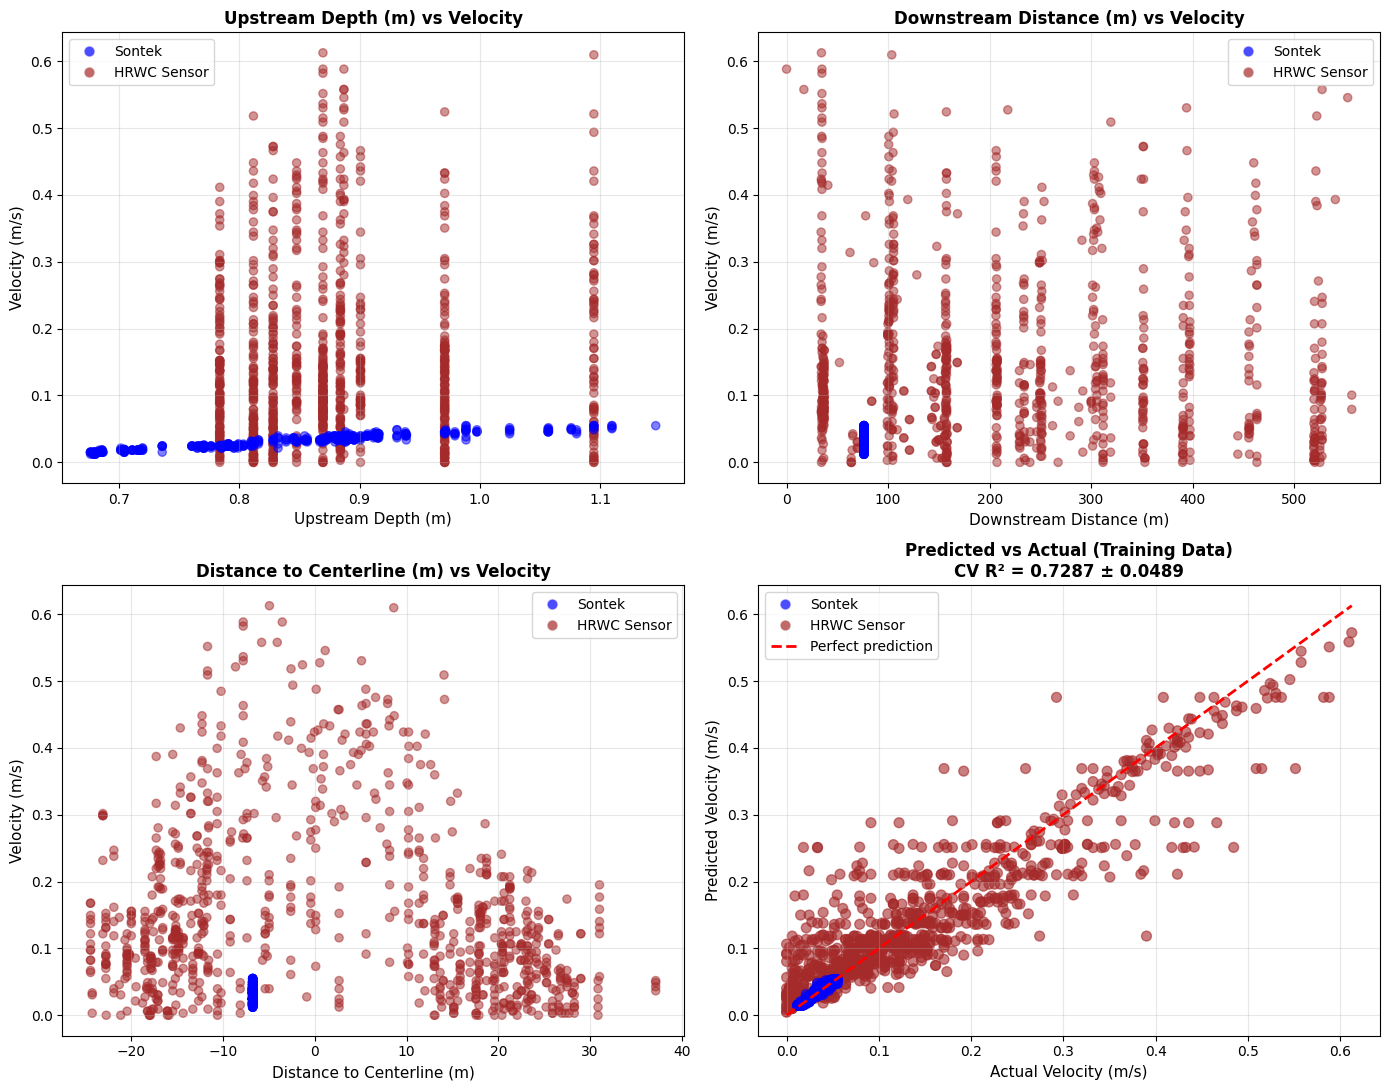


--------------------------------------------------------------------------------
Creating Interactive 2D Heatmap Visualization...
--------------------------------------------------------------------------------

✓ Interactive 2D Heatmap created successfully!
  Resolution: 50x50 grid points
  Distance To Centerline (m) range: [-37.15, 37.15] (symmetric)
  Downstream Dist (m) range: [-3.00, 559.60]
  Actual data - Distance To Centerline (m): [-24.43, 37.15]
  Actual data - Downstream Dist (m): [0.00, 556.60]
  Upstream Depth slider range: [0.676, 1.146] m

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.8696000278271998, continuous_update=False, description='Upstream Dep…

<function __main__.plot_velocity_heatmap(upstream_depth)>

In [11]:
### 9) 3v Model Visualizations
# Heat map and 1-to-1 plots

# 2x2 Plot: Each input vs velocity (actual and predicted) + model verification (Predicted vs Actual)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
input_labels = [
    'Upstream Depth (m)', 
    'Downstream Distance (m)', 
    'Distance to Centerline (m)'
]
input_columns = [
    'upstream_depth', 
    'downstream_dist', 
    'distance_to_centerline'
]
inputs = [gp_data_3v[col] for col in input_columns]

# Create color array based on Type: blue for Sontek, brown for HRWC Sensor
point_colors = np.where(gp_data_3v['Type'] == 'Sontek', 'blue', 'brown')

# Create custom legend handles for sensor types
from matplotlib.lines import Line2D
legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, alpha=0.7, label='Sontek'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='brown', markersize=8, alpha=0.7, label='HRWC Sensor')
]

# Scatter: Input vs Actual velocity (colored by sensor type only)
for idx, (ax, input_data, label) in enumerate(zip(axes.flat[:3], inputs, input_labels)):
    # Plot actual values colored by data type (Sontek=blue, HRWC Sensor=brown)
    scatter = ax.scatter(input_data, y_3v, alpha=0.5, c=point_colors, s=35)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('Velocity (m/s)', fontsize=11)
    ax.set_title(f'{label} vs Velocity', fontsize=12, fontweight='bold')
    ax.legend(handles=legend_handles)
    ax.grid(True, alpha=0.3)

# Scatter: Predicted vs Actual (model verification) - colored by sensor type
ax_pred = axes.flat[3]
ax_pred.scatter(y_3v, y_pred_3v, alpha=0.6, c=point_colors, s=50)
ax_pred.plot([y_3v.min(), y_3v.max()], [y_3v.min(), y_3v.max()], 'r--', lw=2)
ax_pred.set_xlabel('Actual Velocity (m/s)', fontsize=11)
ax_pred.set_ylabel('Predicted Velocity (m/s)', fontsize=11)
ax_pred.set_title(f'Predicted vs Actual (Training Data)\nCV R² = {cv_r2_mean:.4f} ± {cv_r2_std:.4f}', fontsize=12, fontweight='bold')
ax_pred.legend(handles=legend_handles + [Line2D([0], [0], color='r', linestyle='--', lw=2, label='Perfect prediction')])
ax_pred.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# =====================================================================
# 2D Heatmap: Velocity Predictions vs Spatial Position (Interactive)
# =====================================================================

print("\n" + "-"*80)
print("Creating Interactive 2D Heatmap Visualization...")
print("-"*80)

# Import widgets for interactivity
from ipywidgets import interact, FloatSlider
from matplotlib.colors import LinearSegmentedColormap

# Create a 2D heatmap showing velocity predictions as a function of
# downstream_dist (y-axis) and distance_to_centerline (x-axis)

# Get range for upstream_depth slider
upstream_depth_min = X_3v[:, 0].min()
upstream_depth_max = X_3v[:, 0].max()
upstream_depth_median = np.median(X_3v[:, 0])

# Create grid for distance_to_centerline (x-axis) and downstream_dist (y-axis)
n_points_heatmap = 50

# For distance_to_centerline, create symmetric range around 0 to show both sides of river
# Get the maximum absolute distance to ensure all data is captured
max_dist_to_centerline = max(abs(X_3v[:, 2].min()), abs(X_3v[:, 2].max()))
distance_to_centerline_range = np.linspace(-max_dist_to_centerline, max_dist_to_centerline, n_points_heatmap)

# Add small buffer to ensure all data points are within the range (3 meters buffer)
downstream_dist_min = X_3v[:, 1].min() - 3
downstream_dist_max = X_3v[:, 1].max() + 3
downstream_dist_range = np.linspace(downstream_dist_min, downstream_dist_max, n_points_heatmap)

# Create meshgrid
distance_to_centerline_grid, downstream_dist_grid = np.meshgrid(distance_to_centerline_range, downstream_dist_range)

# Create custom colormap that has white at 0
# Using a white-to-color gradient
colors_list = ['white', '#FEF0D9', '#FDCC8A', '#FC8D59', '#E34A33', '#B30000']
n_bins = 100
cmap_custom = LinearSegmentedColormap.from_list('custom_velocity', colors_list, N=n_bins)

# Define the interactive heatmap function
def plot_velocity_heatmap(upstream_depth):
    """
    Generate velocity heatmap for given upstream_depth value
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in feet
    """
    # Create prediction grid with fixed values for other variables
    X_heatmap = np.column_stack([
        np.full(distance_to_centerline_grid.size, upstream_depth),         # upstream_depth (from slider)
        downstream_dist_grid.ravel(),                                       # downstream_dist (varies)
        distance_to_centerline_grid.ravel()                                # distance_to_centerline (varies)
    ])
    
    # Scale the input
    X_heatmap_scaled = scaler_X_3v.transform(X_heatmap)
    
    # Make predictions
    y_heatmap_scaled = gp_model_3v.predict(X_heatmap_scaled)
    
    # Transform back to original scale
    y_heatmap = scaler_y_3v.inverse_transform(y_heatmap_scaled.reshape(-1, 1)).ravel()
    
    # Reshape for heatmap
    velocity_heatmap = y_heatmap.reshape(downstream_dist_grid.shape)
    
    # Create the heatmap figure with normal aspect ratio
    fig_heatmap, ax_heatmap = plt.subplots(figsize=(14, 10))
    
    # Create heatmap using pcolormesh
    # vmin=0 ensures 0 velocity corresponds to white color
    heatmap = ax_heatmap.pcolormesh(
        distance_to_centerline_grid, 
        downstream_dist_grid, 
        velocity_heatmap,
        cmap=cmap_custom,
        shading='auto',
        vmin=0,
        vmax=velocity_heatmap.max()
    )
    
    # Invert y-axis so 0 is at top
    ax_heatmap.invert_yaxis()
    
    # Add colorbar
    cbar = plt.colorbar(heatmap, ax=ax_heatmap)
    cbar.set_label(output_label_3v, rotation=270, labelpad=20, fontsize=13)
    
    # Overlay actual data points
    scatter_actual = ax_heatmap.scatter(
        X_3v[:, 2],  # distance_to_centerline
        X_3v[:, 1],  # downstream_dist
        c=y_3v,      # actual velocity1
        s=120,
        edgecolors='black',
        linewidths=2,
        cmap=cmap_custom,
        vmin=0,
        vmax=velocity_heatmap.max(),
        alpha=0.9,
        label='Actual Measurements',
        zorder=10
    )
    
    # Labels and title
    ax_heatmap.set_xlabel(input_label_3_3v + ' (negative = left, positive = right)', fontsize=14)
    ax_heatmap.set_ylabel(input_label_2_3v, fontsize=14)
    ax_heatmap.set_title(
        f'2D Velocity Prediction Heatmap (Interactive)\n' +
        f'{format_label_3v(input_columns_3v[0])} = {upstream_depth:.2f} {input_unit_1_3v}',
        fontsize=13,
        fontweight='bold',
        pad=20
    )
    
    ax_heatmap.legend(loc='upper right', fontsize=12, framealpha=0.9)
    ax_heatmap.grid(True, alpha=0.2, linestyle='--', color='gray')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n--- Heatmap Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.3f} {input_unit_1_3v}")
    print(f"  Predicted velocity range: [{velocity_heatmap.min():.3f}, {velocity_heatmap.max():.3f}] {output_unit_3v}")
    print(f"  Mean predicted velocity: {velocity_heatmap.mean():.3f} {output_unit_3v}")

# Create interactive widget with slider
print(f"\n✓ Interactive 2D Heatmap created successfully!")
print(f"  Resolution: {n_points_heatmap}x{n_points_heatmap} grid points")
print(f"  {input_label_3_3v} range: [{-max_dist_to_centerline:.2f}, {max_dist_to_centerline:.2f}] (symmetric)")
print(f"  {input_label_2_3v} range: [{downstream_dist_min:.2f}, {downstream_dist_max:.2f}]")
print(f"  Actual data - {input_label_3_3v}: [{X_3v[:, 2].min():.2f}, {X_3v[:, 2].max():.2f}]")
print(f"  Actual data - {input_label_2_3v}: [{X_3v[:, 1].min():.2f}, {X_3v[:, 1].max():.2f}]")
print(f"  Upstream Depth slider range: [{upstream_depth_min:.3f}, {upstream_depth_max:.3f}] {input_unit_1_3v}")
print(f"\nUse the slider below to adjust {format_label_3v(input_columns_3v[0])}:")

# Display interactive widget
interact(
    plot_velocity_heatmap,
    upstream_depth=FloatSlider(
        value=upstream_depth_median,
        min=upstream_depth_min,
        max=upstream_depth_max,
        step=(upstream_depth_max - upstream_depth_min) / 50,
        description=f'{format_label_3v(input_columns_3v[0])}:',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)


STEP 1: Setting up centerline reference
Centerline geometry type: MultiLineString
Reference distance along centerline: 263765.81 meters

Diagnostic check:
Min projected distance in gp_data_3v: 263765.81
Min downstream_dist in gp_data_3v: 0.00
Expected: if downstream_dist was calculated correctly, min should be ~0
Actual min downstream_dist value: 0.000000

STEP 2: Defining inverse transformation function
✓ Inverse transformation function defined

STEP 3: Creating grid in model input space
Downstream distance range: [0.00, 556.60] m
Centerline distance range: [-24.43, 37.15] m
✓ Grid created: 50 × 50 = 2500 points

STEP 4: Evaluating GP model on grid
Using fixed upstream depth: 0.868 m
✓ Predictions complete
Velocity range: [-0.0330, 0.5769] m/s (before clipping)
Velocity range: [0.0000, 0.5769] m/s (after clipping negative values)

STEP 5: Transforming grid to spatial coordinates (geometric inversion)
✓ Grid transformed to spatial coordinates
Easting range: [13244725.21, 13245383.92] f

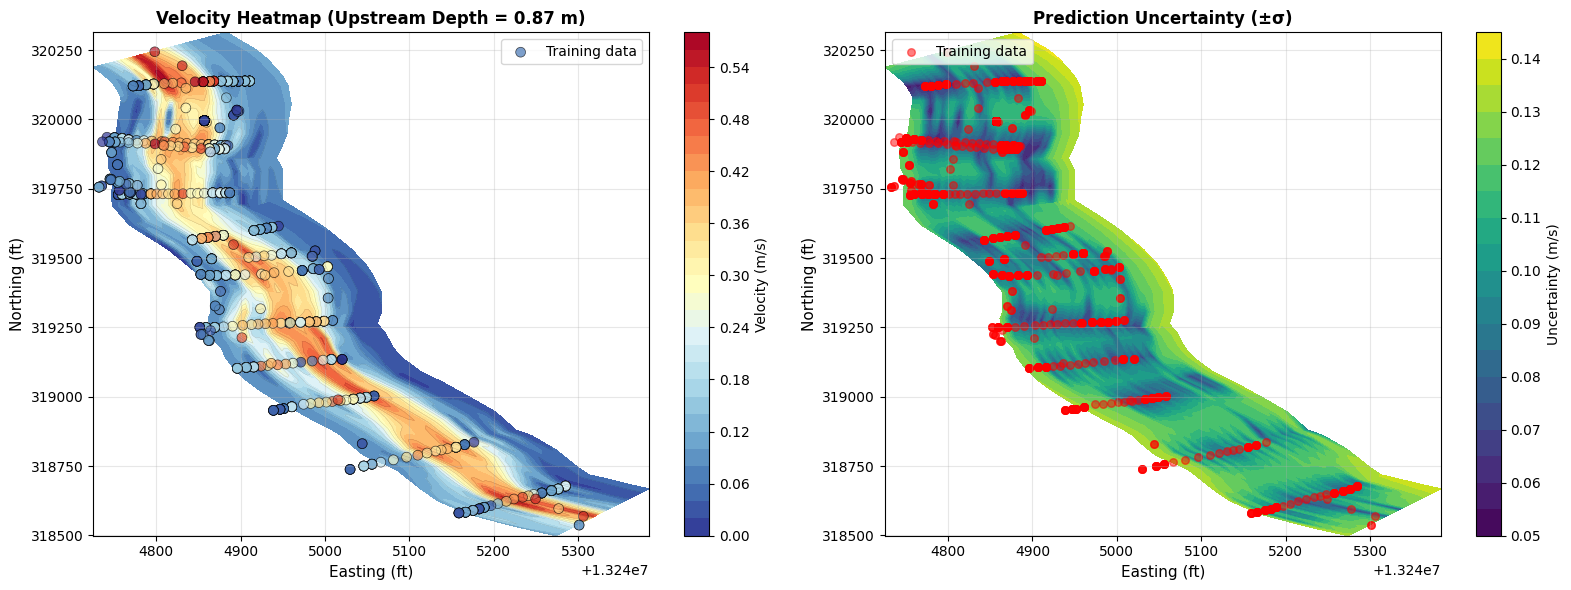

✓ Visualization complete!

STEP 7 (Optional): Exporting results
✓ Results exported to 'gp_spatial_heatmap_results.csv'
✓ Results exported to 'gp_spatial_heatmap_results.geojson'


In [12]:
### 10) Project Model Back to NAD 1983 State Plane Michigan South (feet)

# Option to use mean upstream depth from training data
upstream_depth_value = gp_data_3v['upstream_depth'].mean()

# Define grid resolution (adjust as needed for smoothness vs computation time)
grid_resolution = 50  # Number of points along each dimension (increased for smoother results)import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Point, LineString
import pandas as pd

# =====================================================================
# STEP 1: GET REFERENCE DISTANCE AND CENTERLINE
# =====================================================================

print("="*80)
print("STEP 1: Setting up centerline reference")
print("="*80)

# Get the centerline geometry (same as used in your original calculation)
centerline_geom = centerline.geometry.union_all()

print(f"Centerline geometry type: {centerline_geom.geom_type}")

# Calculate reference distance (same as original downstream_dist calculation)
projected_distances = []
for idx, row in complete_data_25FINAL.iterrows():
    point = row.geometry
    distance_along_centerline = centerline_geom.project(point)
    projected_distances.append(distance_along_centerline)

reference_distance = min(projected_distances)
print(f"Reference distance along centerline: {reference_distance:.2f} meters")

# DIAGNOSTIC: Check if reference_distance matches what was used to create downstream_dist
print(f"\nDiagnostic check:")
print(f"Min projected distance in gp_data_3v: {min(projected_distances):.2f}")
print(f"Min downstream_dist in gp_data_3v: {gp_data_3v['downstream_dist'].min():.2f}")
print(f"Expected: if downstream_dist was calculated correctly, min should be ~0")
print(f"Actual min downstream_dist value: {gp_data_3v['downstream_dist'].min():.6f}")


# =====================================================================
# STEP 2: DEFINE INVERSE TRANSFORMATION FUNCTION
# =====================================================================

print("\n" + "="*80)
print("STEP 2: Defining inverse transformation function")
print("="*80)

def model_to_spatial(downstream_dist, distance_to_centerline):
    """
    Transform from model input space to spatial coordinates using geometric inversion.
    
    Parameters:
    -----------
    downstream_dist : array-like
        Downstream distance(s) in meters (from SI-converted gp_data_3v)
    distance_to_centerline : array-like
        Signed distance to centerline in meters
        (negative = left of centerline, positive = right)
    
    Returns:
    --------
    easting, northing : arrays
        Spatial coordinates (in feet, matching the CRS)
    """
    # Ensure inputs are numpy arrays
    downstream_dist = np.atleast_1d(downstream_dist)
    distance_to_centerline = np.atleast_1d(distance_to_centerline)
    
    easting_list = []
    northing_list = []
    
    # CRITICAL FIX: Convert meters back to feet to match CRS units
    # The centerline geometry and reference_distance are in feet (State Plane CRS)
    # but ds_dist and cl_dist from gp_data_3v are in meters (converted in Cell 29)
    M_TO_FT = 1.0 / FT_TO_M  # = 1/0.3048 ≈ 3.28084
    
    for ds_dist, cl_dist in zip(downstream_dist, distance_to_centerline):
        # Convert from meters to feet before using with centerline geometry
        ds_dist_ft = ds_dist * M_TO_FT
        cl_dist_ft = cl_dist * M_TO_FT
        
        # Step 1: Get point on centerline at this downstream distance
        distance_along_line = reference_distance + ds_dist_ft  # both now in feet
        point_on_centerline = centerline_geom.interpolate(distance_along_line)
        
        # Step 2: Get the direction along the centerline at this point
        # by sampling two nearby points and computing the tangent vector
        epsilon = 0.1  # Small offset for numerical differentiation (in feet)
        p1 = centerline_geom.interpolate(max(0, distance_along_line - epsilon))
        p2 = centerline_geom.interpolate(min(centerline_geom.length, distance_along_line + epsilon))
        
        # Tangent vector (direction along centerline)
        tangent_x = p2.x - p1.x
        tangent_y = p2.y - p1.y
        tangent_length = np.sqrt(tangent_x**2 + tangent_y**2)
        
        if tangent_length < 1e-6:
            # Degenerate case, use the point as-is
            easting_list.append(point_on_centerline.x)
            northing_list.append(point_on_centerline.y)
        else:
            # Normalize tangent vector
            tangent_x /= tangent_length
            tangent_y /= tangent_length
            
            # Perpendicular vector (rotated 90 degrees counterclockwise from tangent)
            # This points to the left of the centerline direction
            perp_x = -tangent_y
            perp_y = tangent_x
            
            # Apply the perpendicular offset (both in feet now)
            final_x = point_on_centerline.x + perp_x * cl_dist_ft
            final_y = point_on_centerline.y + perp_y * cl_dist_ft
            
            easting_list.append(final_x)
            northing_list.append(final_y)
    
    return np.array(easting_list), np.array(northing_list)

print("✓ Inverse transformation function defined")


# =====================================================================
# STEP 3: CREATE GRID IN MODEL INPUT SPACE
# =====================================================================

print("\n" + "="*80)
print("STEP 3: Creating grid in model input space")
print("="*80)

# Define grid resolution (adjust as needed for smoothness vs computation time)
grid_resolution = 50  # Number of points along each dimension (increased for smoother results)

# Get ranges from training data
downstream_min = gp_data_3v['downstream_dist'].min()
downstream_max = gp_data_3v['downstream_dist'].max()
centerline_min = gp_data_3v['distance_to_centerline'].min()
centerline_max = gp_data_3v['distance_to_centerline'].max()

print(f"Downstream distance range: [{downstream_min:.2f}, {downstream_max:.2f}] m")
print(f"Centerline distance range: [{centerline_min:.2f}, {centerline_max:.2f}] m")

# Create 1D arrays for grid
downstream_grid_1d = np.linspace(downstream_min, downstream_max, grid_resolution)
centerline_grid_1d = np.linspace(centerline_min, centerline_max, grid_resolution)

# Create 2D mesh grid
downstream_mesh, centerline_mesh = np.meshgrid(downstream_grid_1d, centerline_grid_1d)

print(f"✓ Grid created: {grid_resolution} × {grid_resolution} = {grid_resolution**2} points")


# =====================================================================
# STEP 4: EVALUATE GP MODEL ON GRID
# =====================================================================

print("\n" + "="*80)
print("STEP 4: Evaluating GP model on grid")
print("="*80)

# Flatten grid for prediction
downstream_flat = downstream_mesh.flatten()
centerline_flat = centerline_mesh.flatten()

upstream_depth_value = upstream_depth_value # set above for interactive setup BUT must be converted

print(f"Using fixed upstream depth: {upstream_depth_value:.3f} m")

# Create input array with all three dimensions
X_grid = np.column_stack([
    np.full_like(downstream_flat, upstream_depth_value),  # upstream_depth (fixed)
    downstream_flat,
    centerline_flat
])

# Scale inputs using the same scaler from training
X_grid_scaled = scaler_X_3v.transform(X_grid)

# Get predictions from GP
velocity_pred_scaled, velocity_std_scaled = gp_model_3v.predict(X_grid_scaled, return_std=True)

# Inverse transform to original scale
velocity_pred = scaler_y_3v.inverse_transform(velocity_pred_scaled.reshape(-1, 1)).ravel()
velocity_std = velocity_std_scaled * scaler_y_3v.scale_

# Reshape back to 2D grid
velocity_grid = velocity_pred.reshape(downstream_mesh.shape)
velocity_std_grid = velocity_std.reshape(downstream_mesh.shape)

# Clip negative velocities to zero (physically unrealistic)
velocity_grid = np.clip(velocity_grid, 0, None)

print(f"✓ Predictions complete")
print(f"Velocity range: [{velocity_pred.min():.4f}, {velocity_pred.max():.4f}] m/s (before clipping)")
print(f"Velocity range: [{velocity_grid.min():.4f}, {velocity_grid.max():.4f}] m/s (after clipping negative values)")


# =====================================================================
# STEP 5: TRANSFORM GRID TO SPATIAL COORDINATES
# =====================================================================

print("\n" + "="*80)
print("STEP 5: Transforming grid to spatial coordinates (geometric inversion)")
print("="*80)

# Transform grid points to spatial coordinates using geometric inversion
easting_grid_flat, northing_grid_flat = model_to_spatial(downstream_flat, centerline_flat)
easting_grid = easting_grid_flat.reshape(downstream_mesh.shape)
northing_grid = northing_grid_flat.reshape(downstream_mesh.shape)

print(f"✓ Grid transformed to spatial coordinates")
print(f"Easting range: [{easting_grid.min():.2f}, {easting_grid.max():.2f}] ft")
print(f"Northing range: [{northing_grid.min():.2f}, {northing_grid.max():.2f}] ft")


# =====================================================================
# STEP 6: VISUALIZE SPATIAL HEATMAP
# =====================================================================

print("\n" + "="*80)
print("STEP 6: Creating spatial heatmap visualization")
print("="*80)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Heatmap in spatial coordinates
contourf = ax1.contourf(easting_grid, northing_grid, velocity_grid, levels=30, cmap='RdYlBu_r')
contour = ax1.contour(easting_grid, northing_grid, velocity_grid, levels=15, colors='black', alpha=0.2, linewidths=0.3)

# Overlay training data points
scatter = ax1.scatter(gp_data_3v['Easting'], gp_data_3v['Northing'], 
                      c=gp_data_3v['Velocity'], s=50, cmap='RdYlBu_r', 
                      edgecolors='black', linewidth=0.5, alpha=0.7, label='Training data')

ax1.set_xlabel('Easting (ft)', fontsize=11)
ax1.set_ylabel('Northing (ft)', fontsize=11)
ax1.set_title(f'Velocity Heatmap (Upstream Depth = {upstream_depth_value:.2f} m)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
cbar1 = plt.colorbar(contourf, ax=ax1, label='Velocity (m/s)')

# Plot 2: Prediction uncertainty in spatial coordinates
contourf_std = ax2.contourf(easting_grid, northing_grid, velocity_std_grid, levels=20, cmap='viridis')
ax2.scatter(gp_data_3v['Easting'], gp_data_3v['Northing'], 
           s=30, c='red', alpha=0.5, label='Training data')
ax2.set_xlabel('Easting (ft)', fontsize=11)
ax2.set_ylabel('Northing (ft)', fontsize=11)
ax2.set_title('Prediction Uncertainty (±σ)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)
cbar2 = plt.colorbar(contourf_std, ax=ax2, label='Uncertainty (m/s)')

plt.tight_layout()
plt.show()

print(f"✓ Visualization complete!")


# =====================================================================
# OPTIONAL: EXPORT RESULTS TO GEOJSON OR CSV
# =====================================================================

print("\n" + "="*80)
print("STEP 7 (Optional): Exporting results")
print("="*80)

# Create a dataframe with grid results
results_df = pd.DataFrame({
    'easting': easting_grid_flat,
    'northing': northing_grid_flat,
    'velocity': velocity_pred,
    'velocity_uncertainty': velocity_std,
    'downstream_dist': downstream_flat,
    'distance_to_centerline': centerline_flat
})

# Save to CSV
results_df.to_csv('gp_spatial_heatmap_results.csv', index=False)
print("✓ Results exported to 'gp_spatial_heatmap_results.csv'")

# Also create GeoJSON-like output
from shapely.geometry import Point
from geopandas import GeoDataFrame

geometry = [Point(xy) for xy in zip(results_df['easting'], results_df['northing'])]
gdf_results = GeoDataFrame(results_df, geometry=geometry, crs='EPSG:2927')  # Adjust CRS as needed
gdf_results.to_file('gp_spatial_heatmap_results.geojson', driver='GeoJSON')
print("✓ Results exported to 'gp_spatial_heatmap_results.geojson'")

In [13]:
### 11) Interactive Spatial GP Model Visualization with Upstream Depth Slider
# =====================================================================
# Interactive visualization of projected GP model output in spatial coordinates
# Uses single slider for upstream depth to update both velocity and uncertainty plots
# =====================================================================

from ipywidgets import interact, FloatSlider

print("="*80)
print("INTERACTIVE SPATIAL GP MODEL VISUALIZATION")
print("="*80)

# Get upstream depth range from training data (already in SI units - meters)
upstream_depth_min_spatial = gp_data_3v['upstream_depth'].min()
upstream_depth_max_spatial = gp_data_3v['upstream_depth'].max()
upstream_depth_median_spatial = gp_data_3v['upstream_depth'].median()

print(f"\nUpstream Depth Range: [{upstream_depth_min_spatial:.3f}, {upstream_depth_max_spatial:.3f}] m")
print(f"Grid Resolution: {grid_resolution} × {grid_resolution} = {grid_resolution**2} points")

def plot_spatial_heatmap_interactive(upstream_depth):
    """
    Generate interactive spatial heatmap for given upstream_depth value.
    Shows both velocity predictions and uncertainty in spatial coordinates.
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in meters (SI units)
    """
    # Create input array with the selected upstream depth
    X_grid_interactive = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),  # upstream_depth (from slider)
        downstream_flat,                                 # downstream_dist
        centerline_flat                                  # distance_to_centerline
    ])
    
    # Scale inputs using the same scaler from training
    X_grid_interactive_scaled = scaler_X_3v.transform(X_grid_interactive)
    
    # Get predictions from GP with uncertainty
    velocity_pred_interactive_scaled, velocity_std_interactive_scaled = gp_model_3v.predict(
        X_grid_interactive_scaled, return_std=True
    )
    
    # Inverse transform to original scale
    velocity_pred_interactive = scaler_y_3v.inverse_transform(
        velocity_pred_interactive_scaled.reshape(-1, 1)
    ).ravel()
    velocity_std_interactive = velocity_std_interactive_scaled * scaler_y_3v.scale_
    
    # Reshape back to 2D grid
    velocity_grid_interactive = velocity_pred_interactive.reshape(downstream_mesh.shape)
    velocity_std_grid_interactive = velocity_std_interactive.reshape(downstream_mesh.shape)
    
    # Clip negative velocities to zero (physically unrealistic)
    velocity_grid_interactive = np.clip(velocity_grid_interactive, 0, None)
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 8))
    
    # ===== Plot 1: Velocity Heatmap in Spatial Coordinates =====
    contourf1 = ax1.contourf(
        easting_grid, northing_grid, velocity_grid_interactive, 
        levels=30, cmap='RdYlBu_r'
    )
    contour1 = ax1.contour(
        easting_grid, northing_grid, velocity_grid_interactive, 
        levels=15, colors='black', alpha=0.2, linewidths=0.3
    )
    
    # Overlay training data points
    scatter1 = ax1.scatter(
        gp_data_3v['Easting'], gp_data_3v['Northing'], 
        c=gp_data_3v['Velocity'], s=60, cmap='RdYlBu_r', 
        edgecolors='black', linewidth=0.8, alpha=0.8, 
        label='Training Data', zorder=10
    )
    
    ax1.set_xlabel('Easting (ft)', fontsize=12)
    ax1.set_ylabel('Northing (ft)', fontsize=12)
    ax1.set_title(
        f'Velocity Prediction (Spatial Coordinates)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=13, fontweight='bold'
    )
    ax1.legend(loc='upper right', fontsize=10, framealpha=0.9)
    ax1.grid(True, alpha=0.3)
    cbar1 = plt.colorbar(contourf1, ax=ax1)
    cbar1.set_label('Velocity (m/s)', fontsize=11)
    
    # ===== Plot 2: Prediction Uncertainty in Spatial Coordinates =====
    contourf2 = ax2.contourf(
        easting_grid, northing_grid, velocity_std_grid_interactive, 
        levels=20, cmap='viridis'
    )
    
    # Overlay training data points
    scatter2 = ax2.scatter(
        gp_data_3v['Easting'], gp_data_3v['Northing'], 
        s=40, c='red', alpha=0.6, label='Training Data', zorder=10
    )
    
    ax2.set_xlabel('Easting (ft)', fontsize=12)
    ax2.set_ylabel('Northing (ft)', fontsize=12)
    ax2.set_title(
        f'Prediction Uncertainty (±σ)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=13, fontweight='bold'
    )
    ax2.legend(loc='upper left', fontsize=10, framealpha=0.9)
    ax2.grid(True, alpha=0.3)
    cbar2 = plt.colorbar(contourf2, ax=ax2)
    cbar2.set_label('Uncertainty (m/s)', fontsize=11)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n--- Model Output Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.4f} m ({upstream_depth / FT_TO_M:.3f} ft)")
    print(f"  Velocity Range: [{velocity_grid_interactive.min():.4f}, {velocity_grid_interactive.max():.4f}] m/s")
    print(f"  Mean Velocity: {velocity_grid_interactive.mean():.4f} m/s")
    print(f"  Uncertainty Range: [{velocity_std_grid_interactive.min():.4f}, {velocity_std_grid_interactive.max():.4f}] m/s")
    print(f"  Mean Uncertainty: {velocity_std_grid_interactive.mean():.4f} m/s")

# Create interactive widget with slider
print(f"\n✓ Interactive Spatial Visualization Ready!")
print(f"\nUse the slider below to adjust Upstream Depth:")

interact(
    plot_spatial_heatmap_interactive,
    upstream_depth=FloatSlider(
        value=upstream_depth_median_spatial,
        min=upstream_depth_min_spatial,
        max=upstream_depth_max_spatial,
        step=(upstream_depth_max_spatial - upstream_depth_min_spatial) / 50,
        description='Upstream Depth (m):',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)

INTERACTIVE SPATIAL GP MODEL VISUALIZATION

Upstream Depth Range: [0.676, 1.146] m
Grid Resolution: 50 × 50 = 2500 points

✓ Interactive Spatial Visualization Ready!

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.8696000278271998, continuous_update=False, description='Upstream Dep…

<function __main__.plot_spatial_heatmap_interactive(upstream_depth)>

In [14]:
### 12) Interactive Binary Threshold Visualization (Velocity > 0.2 m/s)
# =====================================================================
# Binary color visualization: Red = velocity > threshold, Green = velocity <= threshold
# Uses single slider for upstream depth
# =====================================================================

from ipywidgets import interact, FloatSlider
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

print("="*80)
print("INTERACTIVE BINARY THRESHOLD VISUALIZATION")
print("="*80)

# Define velocity threshold
VELOCITY_THRESHOLD = 0.2  # m/s

print(f"\nVelocity Threshold: {VELOCITY_THRESHOLD} m/s")
print(f"  Red = velocity > {VELOCITY_THRESHOLD} m/s (high velocity)")
print(f"  Green = velocity ≤ {VELOCITY_THRESHOLD} m/s (low velocity)")

# Get upstream depth range from training data (already in SI units - meters)
upstream_depth_min_binary = gp_data_3v['upstream_depth'].min()
upstream_depth_max_binary = gp_data_3v['upstream_depth'].max()
upstream_depth_median_binary = gp_data_3v['upstream_depth'].median()

# Create binary colormap: 0 = green, 1 = red
binary_cmap = ListedColormap(['#2ecc71', '#e74c3c'])  # Green, Red

def calculate_area_below_threshold(upstream_depth, return_bounds=False):
    """Calculate percentage of area below velocity threshold for given upstream depth.
    
    If return_bounds=True, also returns lower and upper bounds based on GP uncertainty.
    """
    X_grid = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),
        downstream_flat,
        centerline_flat
    ])
    X_grid_scaled = scaler_X_3v.transform(X_grid)
    
    # Get predictions with uncertainty
    vel_pred_scaled, vel_std_scaled = gp_model_3v.predict(X_grid_scaled, return_std=True)
    vel_pred = scaler_y_3v.inverse_transform(vel_pred_scaled.reshape(-1, 1)).ravel()
    vel_std = vel_std_scaled * scaler_y_3v.scale_
    
    vel_pred = np.clip(vel_pred, 0, None)
    area_mean = ((vel_pred <= VELOCITY_THRESHOLD).sum() / len(vel_pred)) * 100
    
    if return_bounds:
        # Lower bound: using (vel + std) - fewer points will be below threshold
        vel_upper = np.clip(vel_pred + vel_std, 0, None)
        area_lower = ((vel_upper <= VELOCITY_THRESHOLD).sum() / len(vel_upper)) * 100
        
        # Upper bound: using (vel - std) - more points will be below threshold
        vel_lower = np.clip(vel_pred - vel_std, 0, None)
        area_upper = ((vel_lower <= VELOCITY_THRESHOLD).sum() / len(vel_lower)) * 100
        
        return area_mean, area_lower, area_upper
    
    return area_mean

# Pre-calculate area for all depth values with uncertainty bounds (used for line plot in next cell)
upstream_depth_values = np.linspace(upstream_depth_min_binary, upstream_depth_max_binary, 50)
area_below_threshold_values = []
area_lower_bounds = []
area_upper_bounds = []

for d in upstream_depth_values:
    mean, lower, upper = calculate_area_below_threshold(d, return_bounds=True)
    area_below_threshold_values.append(mean)
    area_lower_bounds.append(lower)
    area_upper_bounds.append(upper)

print(f"✓ Pre-calculated area with uncertainty for {len(upstream_depth_values)} depth values")

def plot_binary_threshold_interactive(upstream_depth):
    """
    Generate interactive binary threshold heatmap for given upstream_depth value.
    Red indicates velocity above threshold, Green indicates velocity at or below threshold.
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in meters (SI units)
    """
    # Create input array with the selected upstream depth
    X_grid_binary = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),  # upstream_depth (from slider)
        downstream_flat,                                 # downstream_dist
        centerline_flat                                  # distance_to_centerline
    ])
    
    # Scale inputs using the same scaler from training
    X_grid_binary_scaled = scaler_X_3v.transform(X_grid_binary)
    
    # Get predictions from GP
    velocity_pred_binary_scaled = gp_model_3v.predict(X_grid_binary_scaled)
    
    # Inverse transform to original scale
    velocity_pred_binary = scaler_y_3v.inverse_transform(
        velocity_pred_binary_scaled.reshape(-1, 1)
    ).ravel()
    
    # Reshape back to 2D grid
    velocity_grid_binary = velocity_pred_binary.reshape(downstream_mesh.shape)
    
    # Clip negative velocities to zero
    velocity_grid_binary = np.clip(velocity_grid_binary, 0, None)
    
    # Create binary classification: 1 = above threshold (red), 0 = below threshold (green)
    binary_grid = (velocity_grid_binary > VELOCITY_THRESHOLD).astype(int)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot binary heatmap
    im = ax.pcolormesh(
        easting_grid, northing_grid, binary_grid,
        cmap=binary_cmap, shading='auto',
        vmin=0, vmax=1
    )
    
    # Add contour line at threshold
    contour_threshold = ax.contour(
        easting_grid, northing_grid, velocity_grid_binary,
        levels=[VELOCITY_THRESHOLD], colors='black', linewidths=2.5, linestyles='--'
    )
    ax.clabel(contour_threshold, fmt=f'{VELOCITY_THRESHOLD} m/s', fontsize=11, inline=True)
    
    # # Overlay training data points with binary coloring
    # training_colors = ['#2ecc71' if v <= VELOCITY_THRESHOLD else '#e74c3c' 
    #                    for v in gp_data_3v['Velocity']]
    # scatter = ax.scatter(
    #     gp_data_3v['Easting'], gp_data_3v['Northing'],
    #     c=training_colors, s=80,
    #     edgecolors='black', linewidth=1.2, alpha=0.9,
    #     label='Training Data', zorder=10
    # )
    
    # Labels and title
    ax.set_xlabel('Easting (ft)', fontsize=13)
    ax.set_ylabel('Northing (ft)', fontsize=13)
    ax.set_title(
        f'Binary Velocity Classification (Threshold = {VELOCITY_THRESHOLD} m/s)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=14, fontweight='bold'
    )
    ax.grid(True, alpha=0.3)
    
    # Calculate statistics
    above_threshold_pct = (binary_grid.sum() / binary_grid.size) * 100
    below_threshold_pct = 100 - above_threshold_pct
    
    # Create custom legend
    legend_elements = [
        Patch(facecolor='#e74c3c', edgecolor='black', label=f'Velocity > {VELOCITY_THRESHOLD} m/s (High)'),
        Patch(facecolor='#2ecc71', edgecolor='black', label=f'Velocity ≤ {VELOCITY_THRESHOLD} m/s (Low)'),
        plt.Line2D([0], [0], color='black', linewidth=2.5, linestyle='--', 
                   label=f'Threshold ({VELOCITY_THRESHOLD} m/s)')
    ]
    legend = ax.legend(handles=legend_elements, loc='upper right', fontsize=11, framealpha=0.95)
    
    # Add area below threshold text underneath the legend
    # Get legend bounding box to position text below it
    ax.text(0.98, 0.76, f'Area below threshold: {below_threshold_pct:.1f}%',
            transform=ax.transAxes, fontsize=11, fontweight='bold',
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='#2ecc71', edgecolor='black', alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n--- Binary Classification Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.4f} m ({upstream_depth / FT_TO_M:.3f} ft)")
    print(f"  Velocity Threshold: {VELOCITY_THRESHOLD} m/s")
    print(f"  Area above threshold (Red): {above_threshold_pct:.1f}%")
    print(f"  Area at/below threshold (Green): {below_threshold_pct:.1f}%")
    print(f"  Velocity Range: [{velocity_grid_binary.min():.4f}, {velocity_grid_binary.max():.4f}] m/s")

# Create interactive widget with slider
print(f"\n✓ Interactive Binary Visualization Ready!")
print(f"\nUse the slider below to adjust Upstream Depth:")

interact(
    plot_binary_threshold_interactive,
    upstream_depth=FloatSlider(
        value=upstream_depth_median_binary,
        min=upstream_depth_min_binary,
        max=upstream_depth_max_binary,
        step=(upstream_depth_max_binary - upstream_depth_min_binary) / 50,
        description='Upstream Depth (m):',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)

INTERACTIVE BINARY THRESHOLD VISUALIZATION

Velocity Threshold: 0.2 m/s
  Red = velocity > 0.2 m/s (high velocity)
  Green = velocity ≤ 0.2 m/s (low velocity)
✓ Pre-calculated area with uncertainty for 50 depth values

✓ Interactive Binary Visualization Ready!

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.8696000278271998, continuous_update=False, description='Upstream Dep…

<function __main__.plot_binary_threshold_interactive(upstream_depth)>

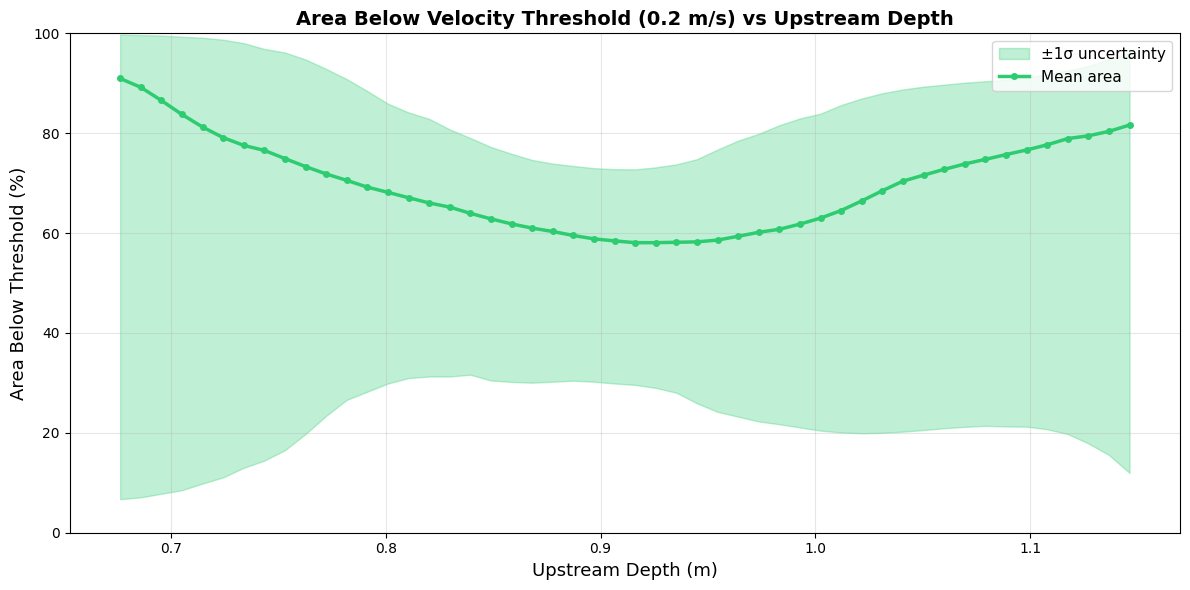

In [15]:
### 13) Area Below Threshold vs Upstream Depth
# =====================================================================
# Line plot using pre-calculated area values with uncertainty bounds
# =====================================================================

fig, ax = plt.subplots(figsize=(12, 6))

# Plot uncertainty band (±1σ based on GP model uncertainty)
ax.fill_between(upstream_depth_values, area_lower_bounds, area_upper_bounds,
                alpha=0.3, color='#2ecc71', label='±1σ uncertainty')

# Plot mean line
ax.plot(upstream_depth_values, area_below_threshold_values, 
        color='#2ecc71', linewidth=2.5, marker='o', markersize=4, label='Mean area')

ax.set_xlabel('Upstream Depth (m)', fontsize=13)
ax.set_ylabel('Area Below Threshold (%)', fontsize=13)
ax.set_title(f'Area Below Velocity Threshold ({VELOCITY_THRESHOLD} m/s) vs Upstream Depth',
             fontsize=14, fontweight='bold')
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', fontsize=11)

plt.tight_layout()
plt.show()
